# Planet Sandbox: Analysis-Ready PlanetScope (Pará, Brazil) via Sentinel Hub

**Why the earlier notebook failed (404):** this sandbox collection (`byoc-3f605f75-86c4-411a-b4ae-01c896f0e54e`, source `PS_ARD_SR_DAILY`) is hosted on **Sentinel Hub** (`services.sentinel-hub.com`), not on `api.planet.com`. Planet API keys only work with `api.planet.com`, and the `/data/collections/v2/...` path does not exist there.

**What this notebook does differently**
- Authenticates with an **OAuth client ID + secret** (not the API key).
- Searches with the Sentinel Hub **Catalog API**.
- Downloads a GeoTIFF with the **Process API**. There is no asset activation step.
- Then shows an RGB preview and NDVI.

**Before running (one time):**
1. Open the Planet Account app: <https://insights.planet.com/account/#/> → **OAuth Clients** → **Create New**.
2. Copy the **client ID** and **client secret** immediately (the secret is shown only once).
3. Your account needs Monitoring Credits (paid or trial). The sandbox data is CC-BY-NC.

The collection covers **2021-01-01 to 2023-12-29** over a 576 km² area centered near (-6.77, -52.38). Requests consume Processing Units from your account.

Never paste your secret into a shared notebook. It is requested with `getpass` below.

## 1. Install packages

In [ ]:
#%pip install requests pandas rasterio matplotlib numpy

Note: you may need to restart the kernel to use updated packages.


## 2. Imports

In [1]:
import json
import time
from pathlib import Path
from getpass import getpass

import numpy as np
import pandas as pd
import requests

## 3. Settings

In [2]:
COLLECTION_ID = "3f605f75-86c4-411a-b4ae-01c896f0e54e"
COLLECTION = f"byoc-{COLLECTION_ID}"

# Area of interest: [west, south, east, north] in EPSG:4326
BBOX = [-52.4825, -6.8735, -52.26725, -6.65775]

# Must fall inside 2021-01-01 .. 2023-12-29
START_DATE = "2022-01-01T00:00:00Z"
END_DATE = "2022-01-31T23:59:59Z"

# Output size in pixels (Process API maximum is 2500 x 2500).
# 2400 px over ~24 km is ~10 m per pixel. The native resolution is 3 m,
# so use a smaller BBOX if you want full resolution.
WIDTH = 2400
HEIGHT = 2400

# Sentinel Hub deployment. The Planet sandbox is normally on the EU one.
# If auth or search says the collection does not exist, try the US one:
#   "https://services-uswest2.sentinel-hub.com"
BASE_URL = "https://services.sentinel-hub.com"

print("Collection:", COLLECTION)
print("Date range:", START_DATE, "to", END_DATE)

Collection: byoc-3f605f75-86c4-411a-b4ae-01c896f0e54e
Date range: 2022-01-01T00:00:00Z to 2022-01-31T23:59:59Z


## 4. Enter your OAuth client credentials (private)

In [8]:
CLIENT_ID = getpass("Planet OAuth client ID: ").strip()
CLIENT_SECRET = getpass("Planet OAuth client secret: ").strip()

if not CLIENT_ID or not CLIENT_SECRET:
    raise RuntimeError("Client ID and secret are both required.")

print("Credentials loaded.")

Credentials loaded.


## 5. Get an access token (cached and refreshed automatically)

In [9]:
_token = {"value": None, "expires_at": 0.0}


def get_token():
    """Return a valid bearer token, fetching a new one only when needed."""
    if _token["value"] and time.time() < _token["expires_at"] - 60:
        return _token["value"]

    r = requests.post(
        f"{BASE_URL}/auth/realms/main/protocol/openid-connect/token",
        data={
            "grant_type": "client_credentials",
            "client_id": CLIENT_ID,
            "client_secret": CLIENT_SECRET,
        },
        timeout=60,
    )

    if not r.ok:
        print("Token request failed:", r.status_code)
        print(r.text[:1000])
        r.raise_for_status()

    data = r.json()
    _token["value"] = data["access_token"]
    _token["expires_at"] = time.time() + int(data.get("expires_in", 3600))
    return _token["value"]


def auth_headers(**extra):
    return {"Authorization": f"Bearer {get_token()}", **extra}


get_token()
print("Authentication succeeded.")

Authentication succeeded.


## 6. Search the Catalog API
Lists the dates that have imagery over your AOI.

In [10]:
def catalog_search(body):
    # Try the documented catalog paths in turn (they are aliases of each other).
    last = None
    for path in ("/api/v1/catalog/1.0.0/search", "/catalog/v1/search"):
        r = requests.post(
            BASE_URL + path,
            headers=auth_headers(**{"Content-Type": "application/json"}),
            json=body,
            timeout=120,
        )
        if r.status_code != 404:
            return r
        last = r
    return last


body = {
    "collections": [COLLECTION],
    "bbox": BBOX,
    "datetime": f"{START_DATE}/{END_DATE}",
    "limit": 100,
}

features = []

for page in range(20):
    r = catalog_search(body)

    if not r.ok:
        print("HTTP status:", r.status_code)
        print(r.text[:2000])
        if r.status_code == 401:
            print("-> Credentials rejected. Check client ID/secret.")
        elif r.status_code == 403:
            print("-> Account may lack access/Monitoring Credits for this collection.")
        elif r.status_code == 404:
            print("-> Try the other deployment (BASE_URL in Cell 3).")
        r.raise_for_status()

    result = r.json()
    features.extend(result.get("features", []))

    nxt = result.get("context", {}).get("next")
    if not nxt:
        break
    body["next"] = nxt

print("Returned features:", len(features))

if not features:
    print("No scenes found. The collection covers 2021-01-01 to 2023-12-29; "
          "check START_DATE/END_DATE and that BBOX is inside the sandbox area.")

Returned features: 10


## 7. Inspect results

In [11]:
if not features:
    raise RuntimeError("No scenes found. See the message above.")

print("Properties available on the first feature:")
print(json.dumps(features[0].get("properties", {}), indent=2)[:1500])

rows = []
for f in features:
    p = f.get("properties", {})
    row = {"id": f.get("id"), "datetime": p.get("datetime")}
    for k, v in p.items():
        if "cloud" in k.lower():
            row[k] = v
    rows.append(row)

results_df = pd.DataFrame(rows)
results_df["date"] = results_df["datetime"].str[:10]
display(results_df.head(30))

print("\nDates with data:", sorted(results_df["date"].unique()))

Properties available on the first feature:
{
  "datetime": "2022-01-26T00:00:00Z",
  "proj:epsg": 32722,
  "proj:bbox": [
    336000.0,
    9240000.0,
    360000.0,
    9264000.0
  ],
  "proj:geometry": {
    "type": "Polygon",
    "crs": {
      "type": "name",
      "properties": {
        "name": "urn:ogc:def:crs:EPSG::32722"
      }
    },
    "coordinates": [
      [
        [
          336000.00000084564,
          9240000.00000001
        ],
        [
          360000.00000031735,
          9240000.000000002
        ],
        [
          360000.0000003204,
          9264000.000000002
        ],
        [
          336000.00000085135,
          9264000.00000001
        ],
        [
          336000.00000084564,
          9240000.00000001
        ]
      ]
    ]
  }
}


,id,datetime,date
0,af6ef170-ada0-447e-9d5f-16d25c4c0bf3,2022-01-26T00:00:00Z,2022-01-26
1,e2bad5da-a626-41d1-8bf4-228d9942a941,2022-01-23T00:00:00Z,2022-01-23
2,681bab29-d1b7-4ef2-9825-8520880ce576,2022-01-22T00:00:00Z,2022-01-22
3,408bc25d-69da-488f-89c1-5a935f1e5ced,2022-01-21T00:00:00Z,2022-01-21
4,44e92a5c-7cd6-4f57-82de-950f51cffffe,2022-01-20T00:00:00Z,2022-01-20
5,5563dd0a-49ee-4da9-97ac-228b0e486e54,2022-01-18T00:00:00Z,2022-01-18
6,716bde8a-2da8-439c-95c1-902a1d1d56a6,2022-01-17T00:00:00Z,2022-01-17
7,bd55435f-99b0-4c12-b4bd-c8baabc2db3b,2022-01-16T00:00:00Z,2022-01-16
8,1c4b2135-9c11-46d0-8639-e480794bd35e,2022-01-14T00:00:00Z,2022-01-14
9,2a5b8e77-06c5-4402-a650-2c4191d60837,2022-01-05T00:00:00Z,2022-01-05



Dates with data: ['2022-01-05', '2022-01-14', '2022-01-16', '2022-01-17', '2022-01-18', '2022-01-20', '2022-01-21', '2022-01-22', '2022-01-23', '2022-01-26']


## 8. Choose a date
By default this picks the date with the lowest cloud cover (if the catalog reports it), otherwise the first date. Override `SELECTED_DATE` to pick your own, e.g. `"2022-01-14"`.

In [12]:
SELECTED_DATE = None  # e.g. "2022-01-14"

cloud_cols = [c for c in results_df.columns if "cloud" in c.lower()]

if SELECTED_DATE is None:
    if cloud_cols:
        per_date = results_df.groupby("date")[cloud_cols[0]].mean().sort_values()
        SELECTED_DATE = per_date.index[0]
        print(f"Lowest mean {cloud_cols[0]}:", round(float(per_date.iloc[0]), 2))
    else:
        SELECTED_DATE = sorted(results_df["date"].unique())[0]

print("Selected date:", SELECTED_DATE)

Selected date: 2022-01-05


## 9. Download a GeoTIFF with the Process API
Tries the standard 4-band surface-reflectance band names first, then the 8-band names. `dataMask` is added as an extra last band (1 = valid pixel).

In [13]:
CANDIDATE_BANDS = [
    ["blue", "green", "red", "nir"],
    ["blue", "green", "red", "nir", "rededge"],
    ["coastal_blue", "blue", "green_i", "green", "yellow", "red", "rededge", "nir"],
]


def build_evalscript(bands):
    inputs = ", ".join(f'"{b}"' for b in bands + ["dataMask"])
    returns = ", ".join(f"s.{b}" for b in bands + ["dataMask"])
    return f"""//VERSION=3
function setup() {{
  return {{
    input: [{{ bands: [{inputs}] }}],
    output: {{ bands: {len(bands) + 1}, sampleType: "FLOAT32" }}
  }};
}}
function evaluatePixel(s) {{
  return [{returns}];
}}
"""


def process_request(bands):
    payload = {
        "input": {
            "bounds": {
                "bbox": BBOX,
                "properties": {"crs": "http://www.opengis.net/def/crs/EPSG/0/4326"},
            },
            "data": [{
                "type": COLLECTION,
                "dataFilter": {
                    "timeRange": {
                        "from": f"{SELECTED_DATE}T00:00:00Z",
                        "to": f"{SELECTED_DATE}T23:59:59Z",
                    },
                    "mosaickingOrder": "mostRecent",
                },
            }],
        },
        "output": {
            "width": WIDTH,
            "height": HEIGHT,
            "responses": [{"identifier": "default", "format": {"type": "image/tiff"}}],
        },
        "evalscript": build_evalscript(bands),
    }
    return requests.post(
        f"{BASE_URL}/api/v1/process",
        headers=auth_headers(**{"Content-Type": "application/json", "Accept": "image/tiff"}),
        json=payload,
        timeout=600,
    )


OUTPUT_DIR = Path("planet_downloads")
OUTPUT_DIR.mkdir(exist_ok=True)
output_file = OUTPUT_DIR / f"ARPS_Para_{SELECTED_DATE}.tif"

used_bands = None

for bands in CANDIDATE_BANDS:
    print("Trying bands:", bands)
    r = process_request(bands)
    print("  HTTP status:", r.status_code)

    if r.ok:
        output_file.write_bytes(r.content)
        used_bands = bands
        break

    print("  ", r.text[:600])
    if r.status_code in (401, 403, 429):
        r.raise_for_status()

if used_bands is None:
    raise RuntimeError(
        "All band sets failed. Read the error text above: it usually names "
        "the invalid band or the access problem. Set CANDIDATE_BANDS to the "
        "band names it reports."
    )

print("Saved:", output_file)
print("File size:", f"{output_file.stat().st_size:,}", "bytes")
print("Bands in file:", used_bands + ["dataMask"])

Trying bands: ['blue', 'green', 'red', 'nir']
  HTTP status: 200
Saved: planet_downloads/ARPS_Para_2022-01-05.tif
File size: 23,097,081 bytes
Bands in file: ['blue', 'green', 'red', 'nir', 'dataMask']


## 10. Read the GeoTIFF

In [14]:
import rasterio

with rasterio.open(output_file) as src:
    print("Driver:", src.driver)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Bands:", src.count)
    print("CRS:", src.crs)
    print("Bounds:", src.bounds)
    print("Resolution:", src.res)
    print("Data type:", src.dtypes)
    image = src.read()

band_index = {name: i for i, name in enumerate(used_bands + ["dataMask"])}
valid = image[band_index["dataMask"]] > 0

print("Array shape:", image.shape)
print("Valid pixels:", f"{valid.mean():.1%}")

Driver: GTiff
Width: 2400
Height: 2400
Bands: 5
CRS: EPSG:4326
Bounds: BoundingBox(left=-52.4825, bottom=-6.8735, right=-52.26725, top=-6.65775)
Resolution: (8.968750000000192e-05, 8.989583333333328e-05)
Data type: ('float32', 'float32', 'float32', 'float32', 'float32')
Array shape: (5, 2400, 2400)
Valid pixels: 40.1%


## 11. Display the image (true color)

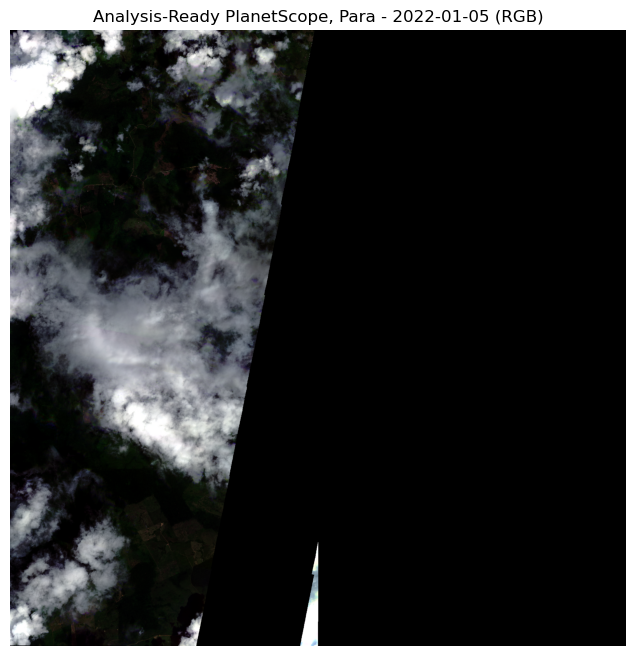

In [15]:
import matplotlib.pyplot as plt


def scale_band(band, mask):
    band = band.astype("float32")
    ok = np.isfinite(band) & mask

    if not ok.any():
        return np.zeros_like(band, dtype="float32")

    low, high = np.percentile(band[ok], [2, 98])

    if high <= low:
        return np.zeros_like(band, dtype="float32")

    out = np.clip((band - low) / (high - low), 0, 1)
    out[~mask] = 0
    return out


red = scale_band(image[band_index["red"]], valid)
green = scale_band(image[band_index["green"]], valid)
blue = scale_band(image[band_index["blue"]], valid)

plt.figure(figsize=(10, 8))
plt.imshow(np.dstack([red, green, blue]))
plt.title(f"Analysis-Ready PlanetScope, Para - {SELECTED_DATE} (RGB)")
plt.axis("off")
plt.show()

## 12. NDVI
NDVI is a ratio, so it does not depend on whether the reflectance values are scaled (the documented ARPS scale is DN/10000).

/var/folders/ng/bkj9rn_n6nq1pb1bjcwzcp500000gn/T/ipykernel_17015/739629877.py:5: RuntimeWarning: invalid value encountered in divide
  ndvi = np.where((den != 0) & valid, (nir_b - red_b) / den, np.nan)


NDVI minimum: -0.21804512
NDVI maximum: 0.96265674
NDVI mean: 0.5783143


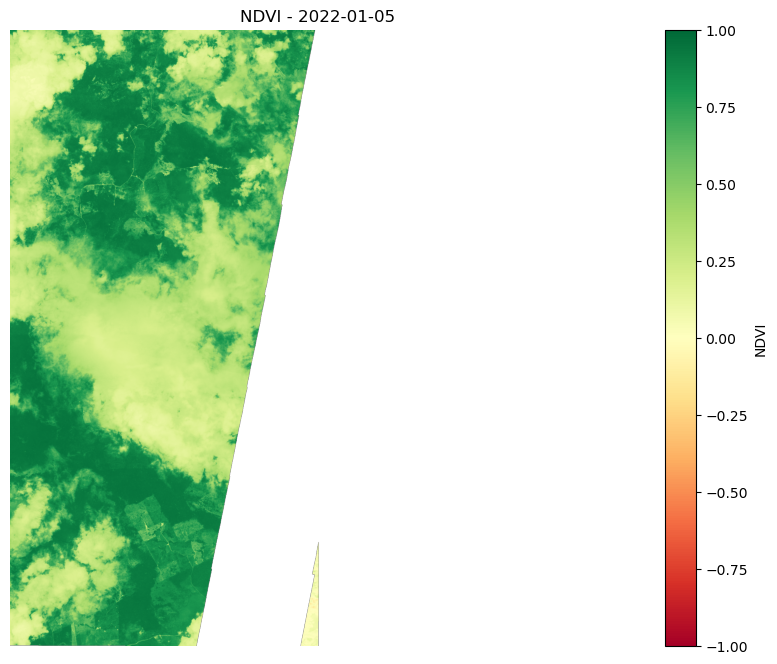

In [16]:
red_b = image[band_index["red"]].astype("float32")
nir_b = image[band_index["nir"]].astype("float32")
den = nir_b + red_b

ndvi = np.where((den != 0) & valid, (nir_b - red_b) / den, np.nan)

print("NDVI minimum:", np.nanmin(ndvi))
print("NDVI maximum:", np.nanmax(ndvi))
print("NDVI mean:", np.nanmean(ndvi))

plt.figure(figsize=(10, 8))
plt.imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
plt.colorbar(label="NDVI")
plt.title(f"NDVI - {SELECTED_DATE}")
plt.axis("off")
plt.show()

## Troubleshooting

| Symptom | Likely cause / fix |
|---|---|
| 401 on token or search | Wrong client ID/secret, or expired OAuth client. Create a new one in the Account app. |
| 403 | Your account has no Monitoring Credits / sandbox access. |
| 404 on search | Collection hosted on the other deployment. Set `BASE_URL = "https://services-uswest2.sentinel-hub.com"`. |
| 0 features | Dates outside 2021-01-01..2023-12-29, or `BBOX` outside the sandbox area (center -6.77, -52.38, 576 km²). |
| 400 invalid band | The error text lists the problem. Edit `CANDIDATE_BANDS` in the download cell. |
| 429 | Too many token or process requests. Wait a minute. |
| Image mostly empty | Pick another date. Use the `dataMask` band and any cloud columns in the results table. |